Splitting data


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

file_path = '/content/drive/MyDrive/PCOS_Project/PCOS_extended_dataset-selected-columns.csv'

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (2000, 21)


,Sl. No,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),Cycle(R/I),...,Marraige Status (Yrs),Pregnant(Y/N),No. of abortions,Weight gain(Y/N),hair growth(Y/N),Skin darkening (Y/N),Hair loss(Y/N),Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N)
0,193,0,32,69.979147,173.7,23.185569,12,72,22,4,...,10.0,1,1,0,1,0,0,1,0,1
1,360,0,34,63.711688,158.2,25.441392,13,78,18,2,...,12.0,1,0,1,0,0,1,1,0,1
2,10,0,22,51.848631,147.2,23.928264,15,72,20,4,...,4.0,0,0,0,0,0,0,0,0,0
3,278,1,27,66.893988,154.9,27.894935,15,74,18,4,...,9.0,0,0,0,1,1,1,0,0,1
4,71,0,27,52.536198,150.9,23.079564,13,72,18,2,...,9.0,0,0,0,0,0,0,0,0,0


In [ ]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df['PCOS (Y/N)']
)

print("Training data:", train_df.shape)
print("Testing data:", test_df.shape)

Training data: (1600, 21)
Testing data: (400, 21)


In [ ]:
train_path = '/content/drive/MyDrive/PCOS_Project/PCOS_train.csv'
test_path = '/content/drive/MyDrive/PCOS_Project/PCOS_test.csv'

train_df.to_csv(train_path, index=False)
test_df.to_csv(test_path, index=False)

print("Training data saved to:", train_path)
print("Testing data saved to:", test_path)

Training data saved to: /content/drive/MyDrive/PCOS_Project/PCOS_train.csv
Testing data saved to: /content/drive/MyDrive/PCOS_Project/PCOS_test.csv


Generate Synthetic Training Data using SMOTE

In [ ]:
import pandas as pd
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTENC

# Load your training dataset
train_path = '/content/drive/MyDrive/PCOS_Project/PCOS_train.csv'
train_df = pd.read_csv(train_path)

# --------------------------------------------------
# 1. Remove Sl. No because it is only an ID
# --------------------------------------------------
train_df = train_df.drop(columns=['Sl. No'])

# --------------------------------------------------
# 2. Separate features and target
# --------------------------------------------------
X_train = train_df.drop(columns=['PCOS (Y/N)'])
y_train = train_df['PCOS (Y/N)']

# --------------------------------------------------
# 3. Categorical columns
# --------------------------------------------------
categorical_columns = [
    'Blood Group',
    'Cycle(R/I)',
    'Pregnant(Y/N)',
    'Weight gain(Y/N)',
    'hair growth(Y/N)',
    'Skin darkening (Y/N)',
    'Hair loss(Y/N)',
    'Pimples(Y/N)',
    'Fast food (Y/N)',
    'Reg.Exercise(Y/N)'
]

# Find the column positions
categorical_indices = [
    X_train.columns.get_loc(column)
    for column in categorical_columns
]

# --------------------------------------------------
# 4. Handle missing values
# --------------------------------------------------
imputer = SimpleImputer(strategy='median')

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns
)

# Make categorical columns integer-valued
for column in categorical_columns:
    X_train_imputed[column] = (
        X_train_imputed[column]
        .round()
        .astype(int)
    )

# --------------------------------------------------
# 5. Apply SMOTENC
# --------------------------------------------------
smotenc = SMOTENC(
    categorical_features=categorical_indices,
    random_state=42
)

X_synthetic, y_synthetic = smotenc.fit_resample(
    X_train_imputed,
    y_train
)

# --------------------------------------------------
# 6. Create final balanced dataset
# --------------------------------------------------
train_smotenc_df = pd.DataFrame(
    X_synthetic,
    columns=X_train.columns
)

train_smotenc_df['PCOS (Y/N)'] = y_synthetic

# --------------------------------------------------
# 7. Display results
# --------------------------------------------------
print("Original training shape:", train_df.shape)
print("SMOTENC training shape:", train_smotenc_df.shape)

print("\nOriginal class distribution:")
print(y_train.value_counts())

print("\nSMOTENC class distribution:")
print(y_synthetic.value_counts())

Original training shape: (1600, 20)
SMOTENC training shape: (2228, 20)

Original class distribution:
PCOS (Y/N)
0    1114
1     486
Name: count, dtype: int64

SMOTENC class distribution:
PCOS (Y/N)
0    1114
1    1114
Name: count, dtype: int64


In [ ]:
# Check missing values
print("Total missing values:",
      train_smotenc_df.isnull().sum().sum())

# Check categorical values
for column in categorical_columns:
    print(f"\n{column}:")
    print(sorted(train_smotenc_df[column].unique()))

# Check first few rows
print("\nSample synthetic training data:")
display(train_smotenc_df.head())

Total missing values: 0

Blood Group:
[np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18)]

Cycle(R/I):
[np.int64(2), np.int64(4), np.int64(5)]

Pregnant(Y/N):
[np.int64(0), np.int64(1)]

Weight gain(Y/N):
[np.int64(0), np.int64(1)]

hair growth(Y/N):
[np.int64(0), np.int64(1)]

Skin darkening (Y/N):
[np.int64(0), np.int64(1)]

Hair loss(Y/N):
[np.int64(0), np.int64(1)]

Pimples(Y/N):
[np.int64(0), np.int64(1)]

Fast food (Y/N):
[np.int64(0), np.int64(1)]

Reg.Exercise(Y/N):
[np.int64(0), np.int64(1)]

Sample synthetic training data:


,Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),Cycle(R/I),Cycle length(days),Marraige Status (Yrs),Pregnant(Y/N),No. of abortions,Weight gain(Y/N),hair growth(Y/N),Skin darkening (Y/N),Hair loss(Y/N),Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),PCOS (Y/N)
0,33.0,66.956754,166.4,24.182902,11,76.0,20.0,2,6.0,11.0,1,0.0,1,0,0,0,1,1,0,0
1,22.0,57.100168,165.9,20.739266,15,72.0,20.0,2,5.0,3.5,0,0.0,0,0,0,0,0,0,0,0
2,28.0,60.871443,166.9,21.857414,11,68.0,20.0,4,5.0,10.0,0,1.0,1,1,0,1,1,1,1,1
3,26.0,46.103125,151.9,19.982361,15,72.0,20.0,2,6.0,8.0,0,0.0,0,0,0,1,1,0,0,0
4,22.0,55.424046,157.1,22.466737,17,72.0,18.0,2,5.0,4.0,0,0.0,0,0,0,0,0,0,0,0


In [ ]:
output_path = '/content/drive/MyDrive/PCOS_Project/PCOS_train_SMOTENC.csv'

train_smotenc_df.to_csv(
    output_path,
    index=False
)

print("SMOTENC dataset saved successfully!")
print("Saved at:", output_path)

SMOTENC dataset saved successfully!
Saved at: /content/drive/MyDrive/PCOS_Project/PCOS_train_SMOTENC.csv


Separate features and target

In [ ]:
import pandas as pd

# Load balanced training data
train_df = pd.read_csv(
    '/content/drive/MyDrive/PCOS_Project/PCOS_train_SMOTENC.csv'
)

# Load untouched test data
test_df = pd.read_csv(
    '/content/drive/MyDrive/PCOS_Project/PCOS_test.csv'
)

# Remove ID column
train_df = train_df.drop(columns=['Sl. No'], errors='ignore')
test_df = test_df.drop(columns=['Sl. No'], errors='ignore')

# Separate features and target
X_train = train_df.drop(columns=['PCOS (Y/N)'])
y_train = train_df['PCOS (Y/N)']

X_test = test_df.drop(columns=['PCOS (Y/N)'])
y_test = test_df['PCOS (Y/N)']

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (2228, 19)
y_train: (2228,)
X_test: (400, 19)
y_test: (400,)


Feature Scaling


In [ ]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (2228, 19)
Scaled testing data shape: (400, 19)


In [ ]:
print(y_train.value_counts())
print(y_test.value_counts())

PCOS (Y/N)
0    1114
1    1114
Name: count, dtype: int64
PCOS (Y/N)
0    278
1    122
Name: count, dtype: int64


Build and train model(ANN)

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# Build ANN model
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3),

    Dense(32, activation='relu'),
    Dropout(0.2),

    Dense(16, activation='relu'),

    Dense(1, activation='sigmoid')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,905 (15.25 KB)

 Trainable params: 3,905 (15.25 KB)

 Non-trainable params: 0 (0.00 B)

Train model

In [ ]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6930 - loss: 0.5986 - val_accuracy: 0.6816 - val_loss: 0.6926
Epoch 2/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8053 - loss: 0.4588 - val_accuracy: 0.7870 - val_loss: 0.5179
Epoch 3/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8384 - loss: 0.4003 - val_accuracy: 0.8027 - val_loss: 0.4920
Epoch 4/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8586 - loss: 0.3593 - val_accuracy: 0.7982 - val_loss: 0.4481
Epoch 5/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8608 - loss: 0.3561 - val_accuracy: 0.8027 - val_loss: 0.3824
Epoch 6/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8659 - loss: 0.3376 - val_accuracy: 0.8004 - val_loss: 0.4004
Epoch 7/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8715 - loss: 0.3221 - val_accuracy: 0.8004 - val_loss: 0.3723
Epoch 8/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8760 - loss: 0.3075 - val_accuracy: 0.7982 - val_loss:

Evaluate model

In [ ]:
import numpy as np

# Predict probabilities
y_pred_prob = model.predict(X_test_scaled)

# Convert probabilities into 0 or 1
y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

print("Predictions generated successfully!")

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
Predictions generated successfully!


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_prob)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("ROC-AUC  :", roc_auc)

Accuracy : 0.9725
Precision: 0.9512195121951219
Recall   : 0.9590163934426229
F1 Score : 0.9551020408163265
ROC-AUC  : 0.990859771199434


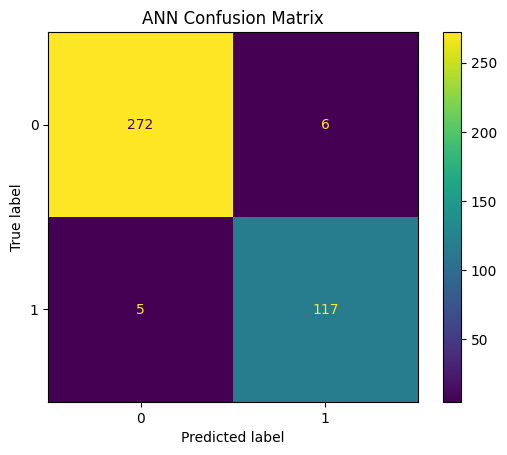

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

plt.title("ANN Confusion Matrix")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98       278
           1       0.95      0.96      0.96       122

    accuracy                           0.97       400
   macro avg       0.97      0.97      0.97       400
weighted avg       0.97      0.97      0.97       400



Training vs Testing Accuracy

In [ ]:
from sklearn.metrics import accuracy_score

# Training predictions
train_pred_prob = model.predict(X_train_scaled)
train_pred = (train_pred_prob >= 0.5).astype(int).flatten()

# Testing predictions
test_pred_prob = model.predict(X_test_scaled)
test_pred = (test_pred_prob >= 0.5).astype(int).flatten()

# Calculate accuracies
train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)

print("Training Accuracy :", train_accuracy)
print("Testing Accuracy  :", test_accuracy)

70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Training Accuracy : 0.9789048473967684
Testing Accuracy  : 0.9725


In [ ]:
print(f"Training Accuracy : {train_accuracy * 100:.2f}%")
print(f"Testing Accuracy  : {test_accuracy * 100:.2f}%")

Training Accuracy : 97.89%
Testing Accuracy  : 97.25%


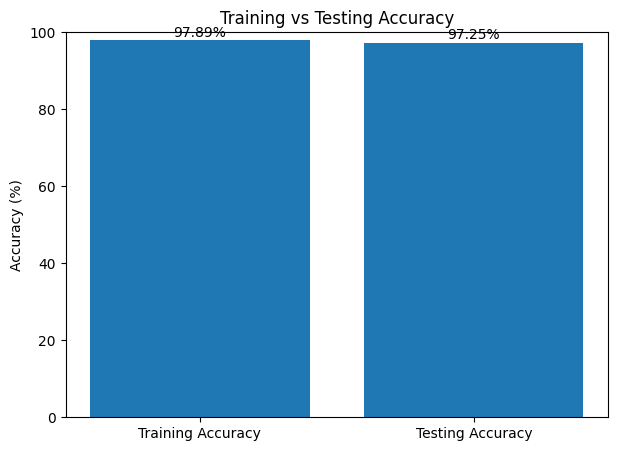

In [ ]:
import matplotlib.pyplot as plt

accuracies = [train_accuracy * 100, test_accuracy * 100]
labels = ['Training Accuracy', 'Testing Accuracy']

plt.figure(figsize=(7, 5))
plt.bar(labels, accuracies)

plt.ylabel("Accuracy (%)")
plt.title("Training vs Testing Accuracy")
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f"{value:.2f}%", ha='center')

plt.show()

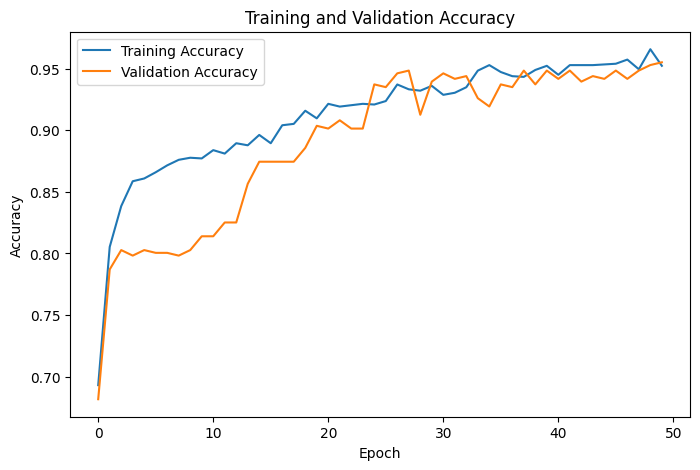

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# -----------------------------
# Training Predictions
# -----------------------------
train_pred_prob = model.predict(X_train_scaled)
train_pred = (train_pred_prob >= 0.5).astype(int).flatten()

# -----------------------------
# Testing Predictions
# -----------------------------
test_pred_prob = model.predict(X_test_scaled)
test_pred = (test_pred_prob >= 0.5).astype(int).flatten()

# -----------------------------
# Training Metrics
# -----------------------------
train_accuracy = accuracy_score(y_train, train_pred)
train_precision = precision_score(y_train, train_pred)
train_recall = recall_score(y_train, train_pred)
train_f1 = f1_score(y_train, train_pred)
train_auc = roc_auc_score(y_train, train_pred_prob)

# -----------------------------
# Testing Metrics
# -----------------------------
test_accuracy = accuracy_score(y_test, test_pred)
test_precision = precision_score(y_test, test_pred)
test_recall = recall_score(y_test, test_pred)
test_f1 = f1_score(y_test, test_pred)
test_auc = roc_auc_score(y_test, test_pred_prob)

# -----------------------------
# Display Results
# -----------------------------
print("========== TRAINING METRICS ==========")
print(f"Accuracy  : {train_accuracy * 100:.2f}%")
print(f"Precision : {train_precision * 100:.2f}%")
print(f"Recall    : {train_recall * 100:.2f}%")
print(f"F1 Score  : {train_f1 * 100:.2f}%")
print(f"ROC-AUC   : {train_auc:.4f}")

print("\n========== TESTING METRICS ==========")
print(f"Accuracy  : {test_accuracy * 100:.2f}%")
print(f"Precision : {test_precision * 100:.2f}%")
print(f"Recall    : {test_recall * 100:.2f}%")
print(f"F1 Score  : {test_f1 * 100:.2f}%")
print(f"ROC-AUC   : {test_auc:.4f}")

70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
========== TRAINING METRICS ==========
Accuracy  : 97.89%
Precision : 98.72%
Recall    : 97.04%
F1 Score  : 97.87%
ROC-AUC   : 0.9969

========== TESTING METRICS ==========
Accuracy  : 97.25%
Precision : 95.12%
Recall    : 95.90%
F1 Score  : 95.51%
ROC-AUC   : 0.9909


Starting with SHAP

In [ ]:
!pip install shap -q

In [ ]:
import shap
import numpy as np
import pandas as pd

In [ ]:
# Select a small background dataset
background = X_train_scaled[:100]

# Create SHAP DeepExplainer
explainer = shap.DeepExplainer(model, background)

# Calculate SHAP values for test data
shap_values = explainer.shap_values(X_test_scaled[:100])

print("SHAP values generated successfully!")

/usr/local/lib/python3.13/dist-packages/shap/explainers/_deep/deep_tf.py:94: UserWarning: Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(100, 19))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(200, 19))']
  warnings.warn(msg)


SHAP values generated successfully!


SHAP Feature importanace

In [ ]:
# Get SHAP values for test samples
shap_values = explainer.shap_values(X_test_scaled[:100])

# Handle different SHAP output formats
if isinstance(shap_values, list):
    shap_values_plot = shap_values[0]
else:
    shap_values_plot = shap_values

# Convert to numpy array
shap_values_plot = np.array(shap_values_plot)

# Remove unnecessary dimensions if present
shap_values_plot = np.squeeze(shap_values_plot)

print("SHAP values shape:", shap_values_plot.shape)
print("Feature data shape:", X_test_scaled[:100].shape)

SHAP values shape: (100, 19)
Feature data shape: (100, 19)


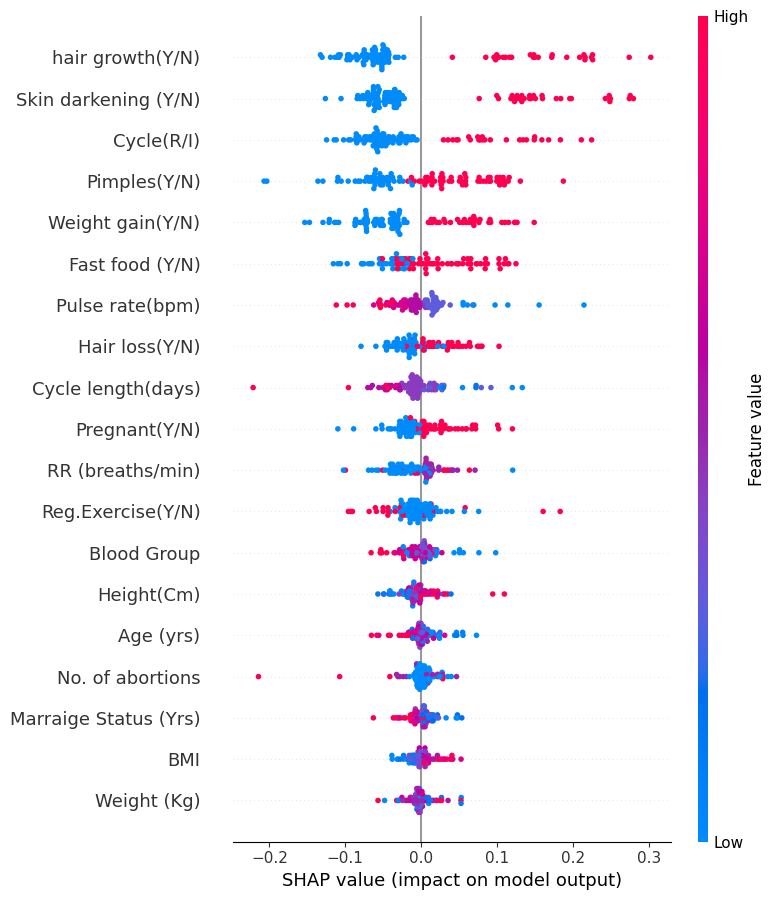

In [ ]:
# Convert scaled test data into DataFrame
X_test_sample = pd.DataFrame(
    X_test_scaled[:100],
    columns=X_test.columns
)

# SHAP summary plot
shap.summary_plot(
    shap_values_plot,
    X_test_sample,
    feature_names=X_test.columns
)

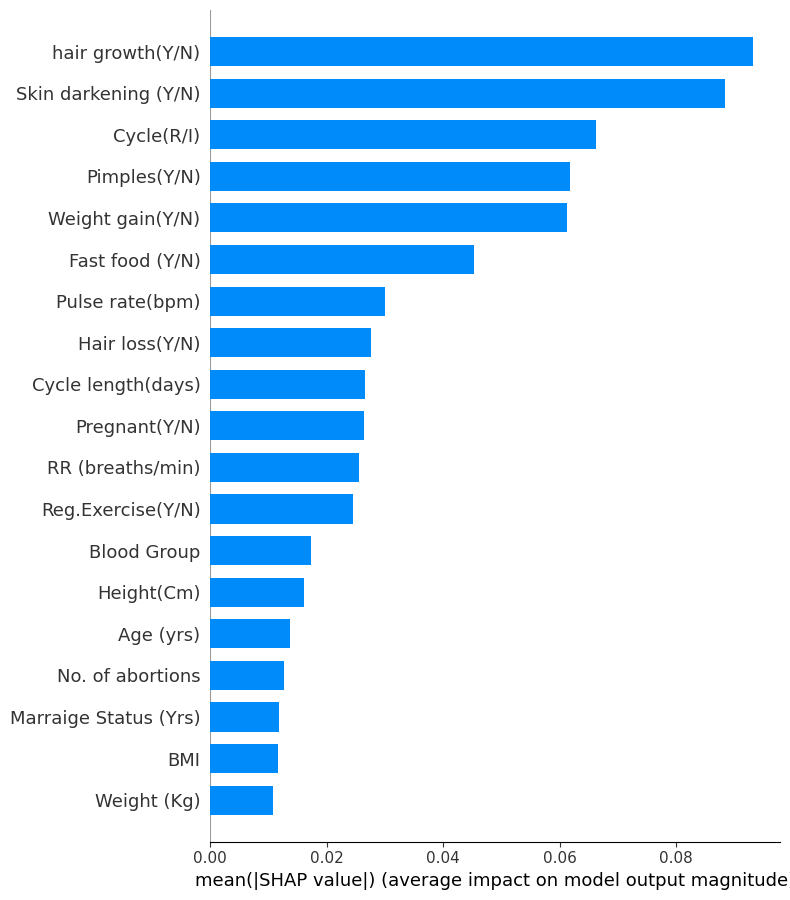

In [ ]:
shap.summary_plot(
    shap_values_plot,
    X_test_sample,
    feature_names=X_test.columns,
    plot_type="bar"
)

LIME Explainable Ai

In [ ]:
!pip install lime -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 1.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
from lime.lime_tabular import LimeTabularExplainer
import numpy as np

In [ ]:
explainer_lime = LimeTabularExplainer(
    X_train_scaled,
    feature_names=X_train.columns.tolist(),
    class_names=["No PCOS", "PCOS"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

In [ ]:
def predict_probability(X):
    prob = model.predict(X, verbose=0)

    return np.hstack([1 - prob, prob])

In [ ]:
patient_index = 0

patient = X_test_scaled[patient_index]

explanation = explainer_lime.explain_instance(
    patient,
    predict_probability,
    num_features=10
)

print("Actual PCOS:", y_test.iloc[patient_index])
print("Predicted PCOS:", test_pred[patient_index])
print("Predicted Probability:", test_pred_prob[patient_index])

Actual PCOS: 0
Predicted PCOS: 0
Predicted Probability: [0.00564646]


In [ ]:
explanation.show_in_notebook(show_table=True)

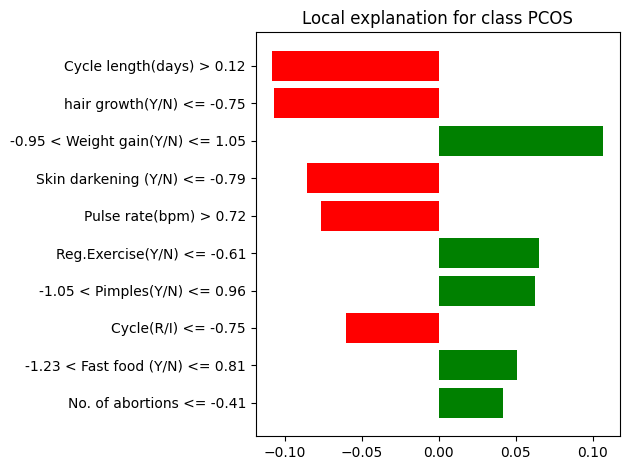

In [ ]:
fig = explanation.as_pyplot_figure()

import matplotlib.pyplot as plt
plt.tight_layout()
plt.show()

Save the model

In [ ]:
# Save ANN model in recommended Keras format
model.save("pcos_ann_model.keras")

# Save scaler
import joblib
joblib.dump(scaler, "pcos_scaler.pkl")

print("ANN model and scaler saved successfully!")

ANN model and scaler saved successfully!


Confusion Matrix


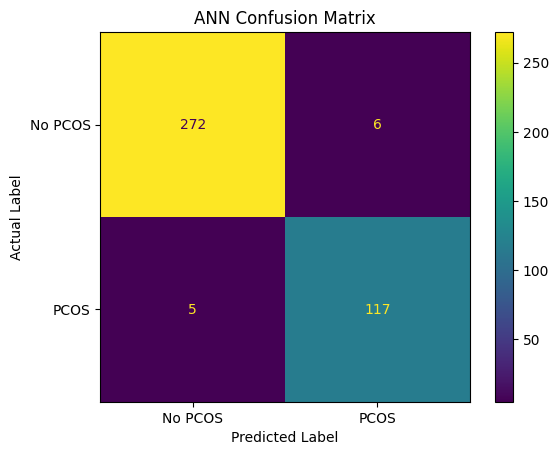

Confusion Matrix:
[[272   6]
 [  5 117]]


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No PCOS", "PCOS"]
)

disp.plot()
plt.title("ANN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

print("Confusion Matrix:")
print(cm)

ROC and AUC curve

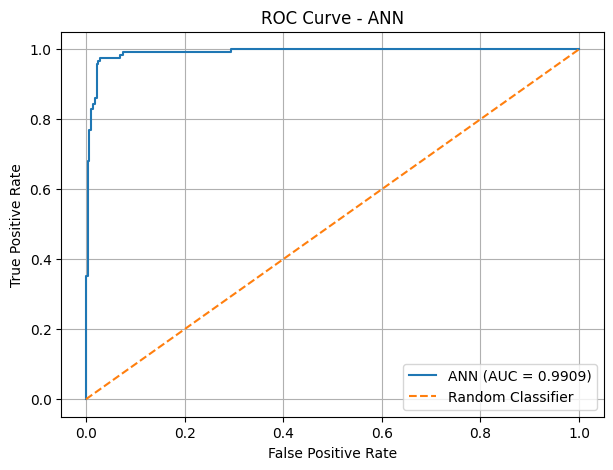

ROC-AUC Score: 0.9909


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

# Calculate ROC-AUC
roc_auc = roc_auc_score(y_test, y_pred_prob)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ANN (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - ANN")
plt.legend()
plt.grid()
plt.show()

print(f"ROC-AUC Score: {roc_auc:.4f}")

precision rcall curve

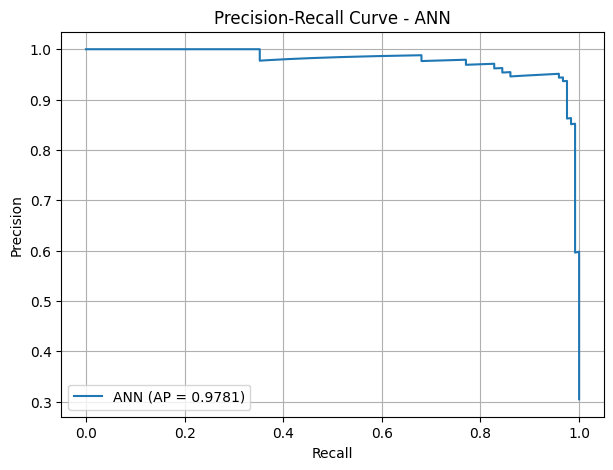

Average Precision Score: 0.9781


In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Calculate precision and recall values
precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_pred_prob
)

# Calculate Average Precision
average_precision = average_precision_score(
    y_test,
    y_pred_prob
)

# Plot Precision-Recall curve
plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    label=f"ANN (AP = {average_precision:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - ANN")
plt.legend()
plt.grid()
plt.show()

print(f"Average Precision Score: {average_precision:.4f}")

Training and validation

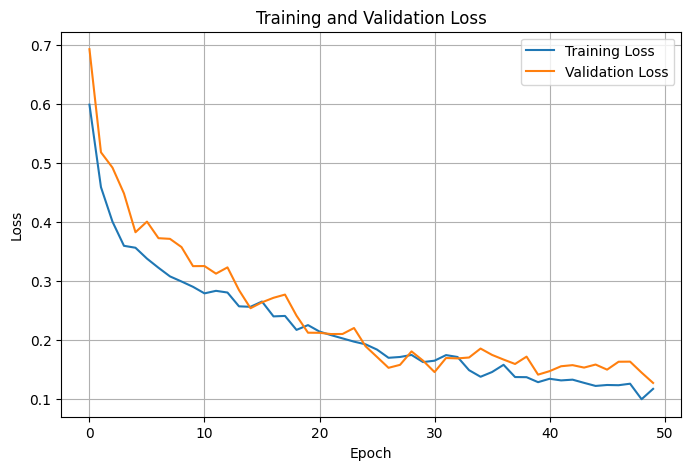

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()


Training and validation accuracy

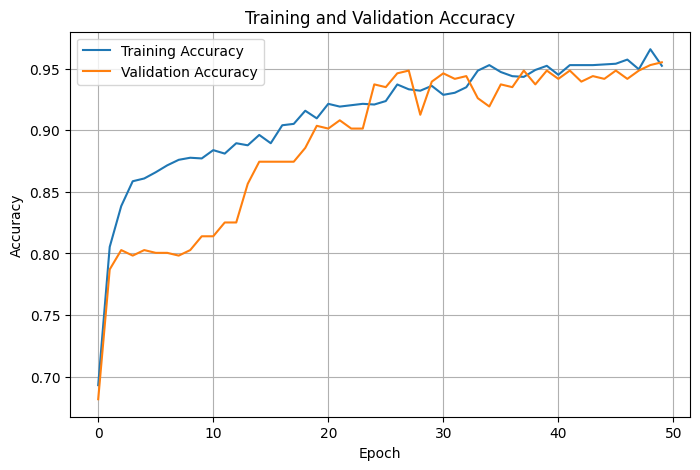

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

Final ANN performance

In [ ]:
import pandas as pd

# Create final performance table
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Training": [
        train_accuracy,
        train_precision,
        train_recall,
        train_f1,
        train_auc
    ],
    "Testing": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_auc
    ]
})

# Convert to percentage except ROC-AUC
results["Training"] = results["Training"].apply(
    lambda x: f"{x * 100:.2f}%" if x <= 1 else f"{x:.4f}"
)

results["Testing"] = results["Testing"].apply(
    lambda x: f"{x * 100:.2f}%" if x <= 1 else f"{x:.4f}"
)

display(results)

,Metric,Training,Testing
0,Accuracy,97.89%,97.25%
1,Precision,98.72%,95.12%
2,Recall,97.04%,95.90%
3,F1 Score,97.87%,95.51%
4,ROC-AUC,99.69%,99.09%


Save results

In [ ]:
# Save results table
results.to_csv(
    "/content/drive/MyDrive/PCOS_Project/ANN_results.csv",
    index=False
)

print("ANN evaluation results saved successfully.")

ANN evaluation results saved successfully.


In [ ]:
import joblib
import os

# Create project folder
os.makedirs("/content/PCOS_Streamlit_Project", exist_ok=True)

# Save ANN model
model.save("/content/PCOS_Streamlit_Project/pcos_ann_model.keras")

# Save scaler
joblib.dump(
    scaler,
    "/content/PCOS_Streamlit_Project/pcos_scaler.pkl"
)

# Save feature names
joblib.dump(
    X_train.columns.tolist(),
    "/content/PCOS_Streamlit_Project/feature_names.pkl"
)

print("Files saved successfully!")
print(os.listdir("/content/PCOS_Streamlit_Project"))

Files saved successfully!
['pcos_scaler.pkl', 'feature_names.pkl', 'pcos_ann_model.keras']


In [ ]:
from google.colab import files

files.download("/content/PCOS_Streamlit_Project/pcos_ann_model.keras")
files.download("/content/PCOS_Streamlit_Project/pcos_scaler.pkl")
files.download("/content/PCOS_Streamlit_Project/feature_names.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(X_train.columns.tolist())

['Age (yrs)', 'Weight (Kg)', 'Height(Cm)', 'BMI', 'Blood Group', 'Pulse rate(bpm)', 'RR (breaths/min)', 'Cycle(R/I)', 'Cycle length(days)', 'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of abortions', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)']


In [ ]:
for col in [
    'Blood Group',
    'Cycle(R/I)',
    'Pregnant(Y/N)',
    'Weight gain(Y/N)',
    'hair growth(Y/N)',
    'Skin darkening (Y/N)',
    'Hair loss(Y/N)',
    'Pimples(Y/N)',
    'Fast food (Y/N)',
    'Reg.Exercise(Y/N)'
]:
    print("\n", col)
    print(sorted(X_train[col].unique()))


 Blood Group
[np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18)]

 Cycle(R/I)
[np.int64(2), np.int64(4), np.int64(5)]

 Pregnant(Y/N)
[np.int64(0), np.int64(1)]

 Weight gain(Y/N)
[np.int64(0), np.int64(1)]

 hair growth(Y/N)
[np.int64(0), np.int64(1)]

 Skin darkening (Y/N)
[np.int64(0), np.int64(1)]

 Hair loss(Y/N)
[np.int64(0), np.int64(1)]

 Pimples(Y/N)
[np.int64(0), np.int64(1)]

 Fast food (Y/N)
[np.int64(0), np.int64(1)]

 Reg.Exercise(Y/N)
[np.int64(0), np.int64(1)]


In [ ]:
sample = X_test.iloc[[0]]

sample_scaled = scaler.transform(sample)

prob = model.predict(sample_scaled, verbose=0)[0][0]

print("Colab probability:", prob)
print("Colab percentage:", prob * 100)

Colab probability: 0.0056464663
Colab percentage: 0.5646466


In [ ]:
sample = X_test.iloc[0]

print(sample)

Age (yrs)                 28.000000
Weight (Kg)               70.494064
Height(Cm)               165.500000
BMI                       25.745752
Blood Group               15.000000
Pulse rate(bpm)           82.000000
RR (breaths/min)          18.000000
Cycle(R/I)                 2.000000
Cycle length(days)         6.000000
Marraige Status (Yrs)      6.000000
Pregnant(Y/N)              1.000000
No. of abortions           0.000000
Weight gain(Y/N)           1.000000
hair growth(Y/N)           0.000000
Skin darkening (Y/N)       0.000000
Hair loss(Y/N)             1.000000
Pimples(Y/N)               1.000000
Fast food (Y/N)            1.000000
Reg.Exercise(Y/N)          0.000000
Name: 0, dtype: float64


In [ ]:
print(df["Blood Group"].value_counts())
print(df["Cycle(R/I)"].value_counts())

Blood Group
15    754
13    500
11    400
17    156
16     70
14     65
12     51
18      4
Name: count, dtype: int64
Cycle(R/I)
2    1466
4     531
5       3
Name: count, dtype: int64


In [ ]:
sample_scaled = scaler.transform(X_test.iloc[[0]])

prob = model.predict(sample_scaled, verbose=0)[0][0]

print("Colab probability:", prob)
print("Colab percentage:", prob * 100)

Colab probability: 0.0056464663
Colab percentage: 0.5646466


In [ ]:
print("Blood Group:")
print(df["Blood Group"].unique())

print("\nCycle:")
print(df["Cycle(R/I)"].unique())

Blood Group:
[12 13 15 11 17 14 16 18]

Cycle:
[4 2 5]
